#  PR 4 — Project A
## CNN from Scratch — CIFAR-10 Image Classifier

### Objective
Build and analyse a CNN for CIFAR-10, covering:
1. Data loading, EDA and preprocessing
2. Convolution, padding and strides
3. Pooling, Flatten, LeNet-5 and a custom CNN
4. Backpropagation and CNN training
5. Data augmentation
6. Transfer learning with MobileNetV2, fine-tuning and a residual block



# Task A1 — Data Loading, EDA & Preprocessing

**Objective:** Load CIFAR-10, inspect the dataset, visualise 5 samples per class, normalise pixel values, one-hot encode labels, and explain CNN vs ANN.

**Comment:** CIFAR-10 contains 60,000 RGB images of size 32×32 belonging to 10 classes. Normalisation converts pixel values from 0–255 to 0–1, which helps gradient-based training. One-hot encoding represents each class as a 10-element vector for the softmax output. CNNs preserve local spatial relationships and reuse the same filter weights across image locations, while an ANN normally flattens the image first.

**Expected output:** Dataset shapes, unique labels, 5×10 sample grid, pixel histograms before/after normalisation, one-hot shape, and CNN-vs-ANN explanation.

In [1]:
# A1.1 Imports and reproducibility
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from scipy.signal import convolve2d
from sklearn.metrics import confusion_matrix, classification_report

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
random.seed(SEED)

print("TensorFlow:", tf.__version__)
print("Num GPUs:", len(tf.config.list_physical_devices("GPU")))

TensorFlow: 2.21.0
Num GPUs: 0


In [2]:
# A1.1 Load CIFAR-10
(X_train, y_train), (X_test, y_test) = keras.datasets.cifar10.load_data()

print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape :", y_test.shape)
print("Unique y values:", np.unique(y_train))
print("X_train dtype:", X_train.dtype)

X_train shape: (50000, 32, 32, 3)
X_test shape : (10000, 32, 32, 3)
y_train shape: (50000, 1)
y_test shape : (10000, 1)
Unique y values: [0 1 2 3 4 5 6 7 8 9]
X_train dtype: uint8


In [3]:
# CIFAR-10 class names
class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

print(dict(enumerate(class_names)))
print("Training images:", len(X_train))
print("Test images:", len(X_test))

{0: 'airplane', 1: 'automobile', 2: 'bird', 3: 'cat', 4: 'deer', 5: 'dog', 6: 'frog', 7: 'horse', 8: 'ship', 9: 'truck'}
Training images: 50000
Test images: 10000


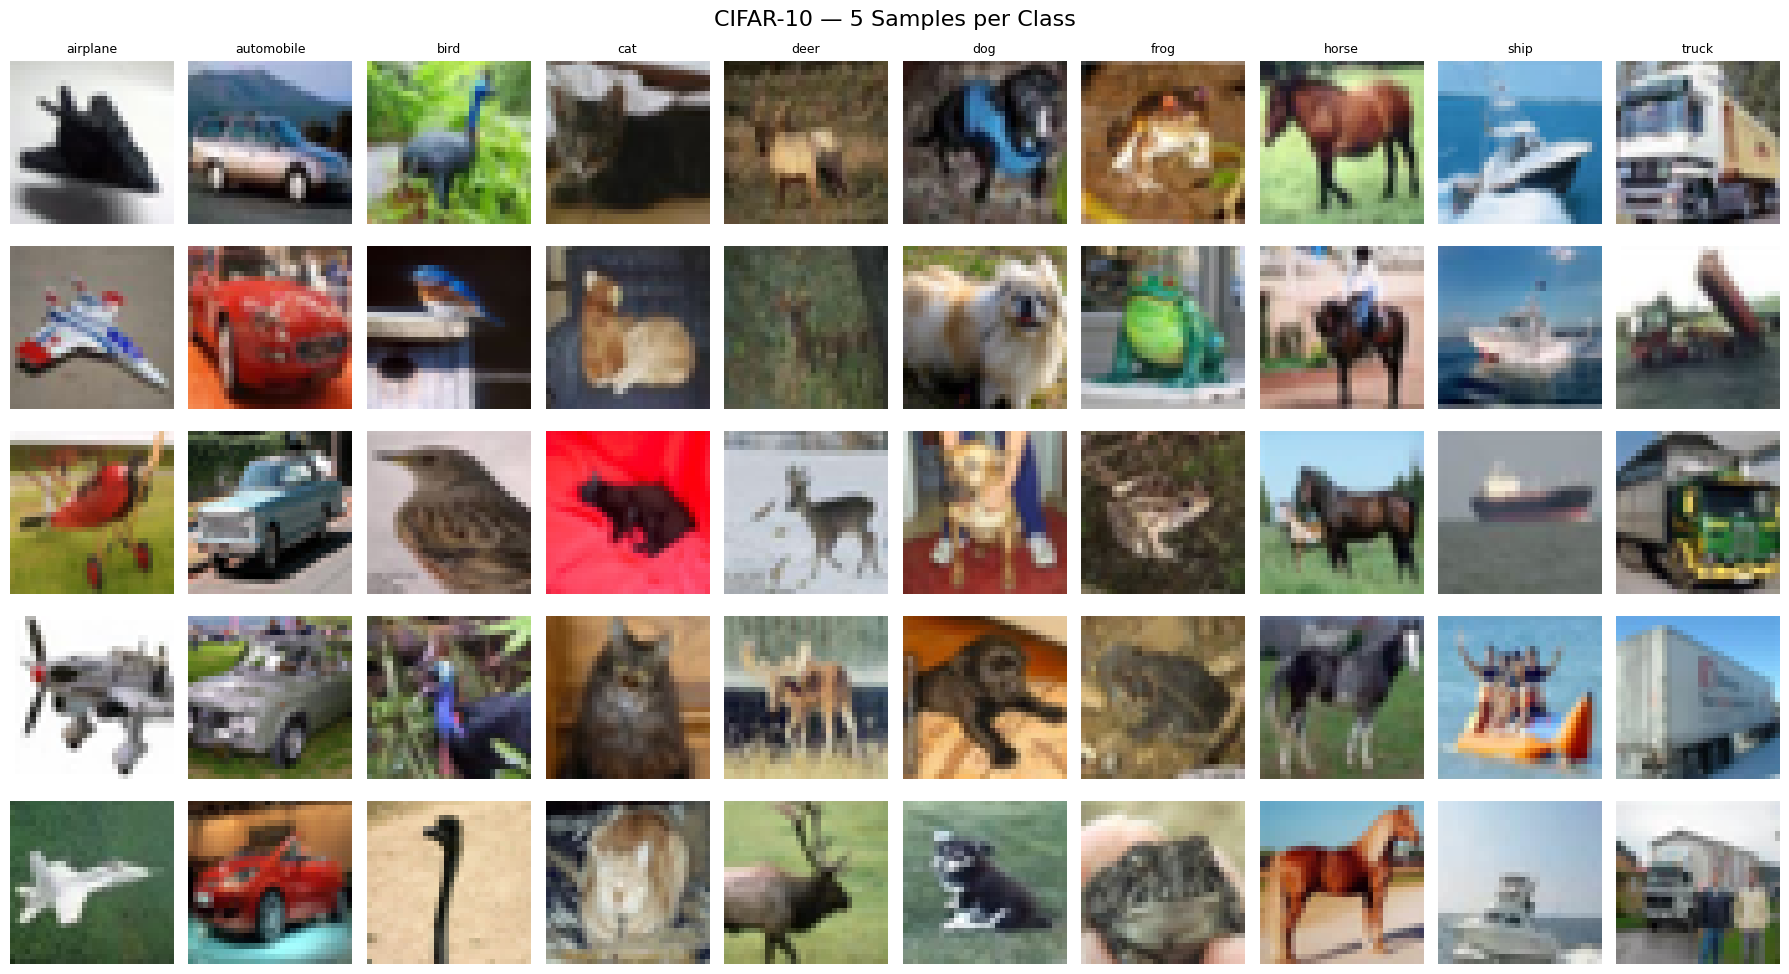

In [4]:
# A1.2 Visualise 5 samples per class — 5×10 grid
fig, axes = plt.subplots(5, 10, figsize=(18, 10))

for class_id in range(10):
    idxs = np.where(y_train.flatten() == class_id)[0][:5]
    for row, idx in enumerate(idxs):
        axes[row, class_id].imshow(X_train[idx])
        axes[row, class_id].axis("off")
        if row == 0:
            axes[row, class_id].set_title(class_names[class_id], fontsize=9)

fig.suptitle("CIFAR-10 — 5 Samples per Class", fontsize=16)
plt.tight_layout()
plt.show()

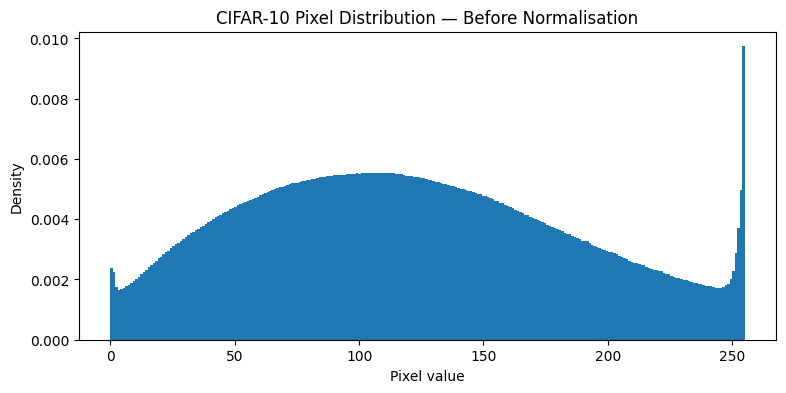

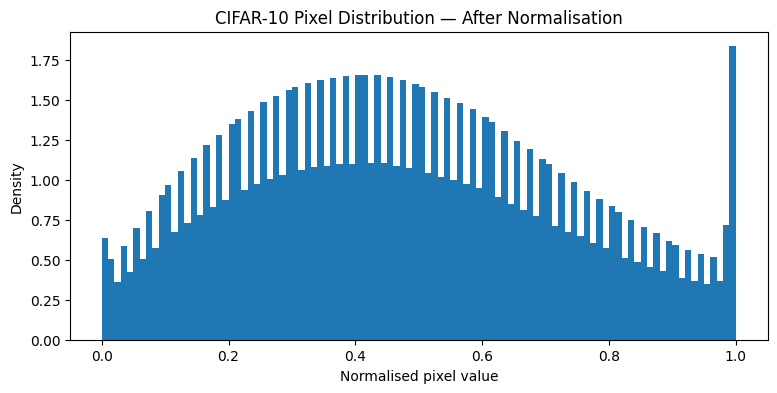

Min: 0.0 Max: 1.0


In [5]:
# A1.3 Pixel distribution before normalisation
plt.figure(figsize=(9, 4))
plt.hist(X_train.flatten(), bins=256, range=(0, 255), density=True)
plt.title("CIFAR-10 Pixel Distribution — Before Normalisation")
plt.xlabel("Pixel value")
plt.ylabel("Density")
plt.show()

# Normalise to [0, 1]
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

plt.figure(figsize=(9, 4))
plt.hist(X_train.flatten(), bins=100, range=(0, 1), density=True)
plt.title("CIFAR-10 Pixel Distribution — After Normalisation")
plt.xlabel("Normalised pixel value")
plt.ylabel("Density")
plt.show()

print("Min:", X_train.min(), "Max:", X_train.max())

In [6]:
# A1.4 One-hot encode labels
y_train_ohe = keras.utils.to_categorical(y_train, 10)
y_test_ohe = keras.utils.to_categorical(y_test, 10)

print("y_train_ohe shape:", y_train_ohe.shape)
print("y_test_ohe shape :", y_test_ohe.shape)

y_train_ohe shape: (50000, 10)
y_test_ohe shape : (10000, 10)


# Task A2 — Convolution Operation, Padding & Strides

**Objective:** Demonstrate convolution manually, compare VALID and SAME padding, compare stride 1 and stride 2, and visualise 16 CNN feature maps.

**Comment:** Convolution applies a small kernel to local image patches and produces a feature map. VALID padding does not add borders, so a 32×32 image with a 3×3 kernel and stride 1 becomes 30×30. SAME padding preserves 32×32 for stride 1. Stride controls how far the filter moves; stride 2 reduces the spatial size. Feature maps show the response of individual learnable filters.

**Expected output:** Manual convolution image, padding output shapes, stride output shapes, and 4×4 feature-map grid.

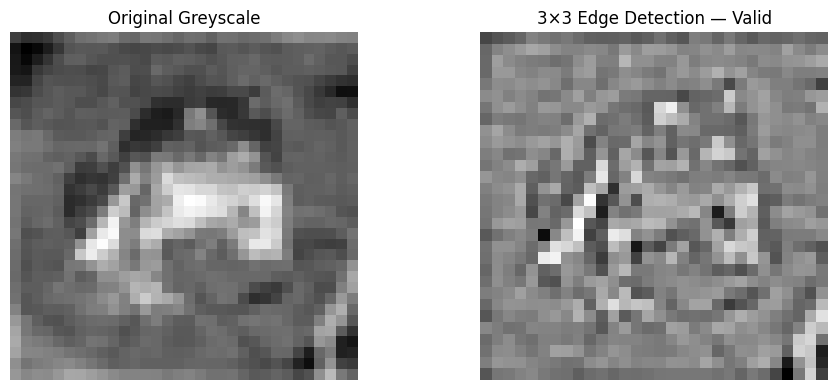

Input shape: (32, 32)
Convolved shape: (30, 30)


In [7]:
# A2.1 Manual convolution on one greyscale image
gray = np.mean(X_train[0], axis=2)

edge_kernel = np.array([
    [-1, -1, -1],
    [-1,  8, -1],
    [-1, -1, -1]
], dtype=np.float32)

convolved = convolve2d(gray, edge_kernel, mode="valid")

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].imshow(gray, cmap="gray")
ax[0].set_title("Original Greyscale")
ax[0].axis("off")

ax[1].imshow(convolved, cmap="gray")
ax[1].set_title("3×3 Edge Detection — Valid")
ax[1].axis("off")
plt.tight_layout()
plt.show()

print("Input shape:", gray.shape)
print("Convolved shape:", convolved.shape)

In [8]:
# A2.2 VALID vs SAME padding
test_img = X_train[0:1]

model_valid = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(8, (3, 3), padding="valid")
])

model_same = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(8, (3, 3), padding="same")
])

out_valid = model_valid(test_img)
out_same = model_same(test_img)

print("VALID output:", out_valid.shape)
print("SAME output :", out_same.shape)

print("VALID formula: output = floor((input - kernel) / stride) + 1")
print("For 32×32, kernel=3, stride=1 -> 30×30")
print("SAME with stride=1 -> 32×32")

VALID output: (1, 30, 30, 8)
SAME output : (1, 32, 32, 8)
VALID formula: output = floor((input - kernel) / stride) + 1
For 32×32, kernel=3, stride=1 -> 30×30
SAME with stride=1 -> 32×32


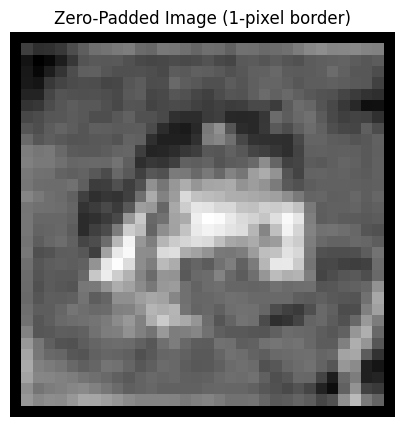

In [9]:
# Visualise zero padding
padded = np.pad(gray, pad_width=1, mode="constant", constant_values=0)

plt.figure(figsize=(5, 5))
plt.imshow(padded, cmap="gray")
plt.title("Zero-Padded Image (1-pixel border)")
plt.axis("off")
plt.show()

In [10]:
# A2.3 Stride comparison
model_s1 = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(8, (3, 3), strides=1, padding="same")
])

model_s2 = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(8, (3, 3), strides=2, padding="same")
])

print("Stride=1 output:", model_s1(test_img).shape)
print("Stride=2 output:", model_s2(test_img).shape)

Stride=1 output: (1, 32, 32, 8)
Stride=2 output: (1, 16, 16, 8)


Feature map tensor: (32, 32, 16)


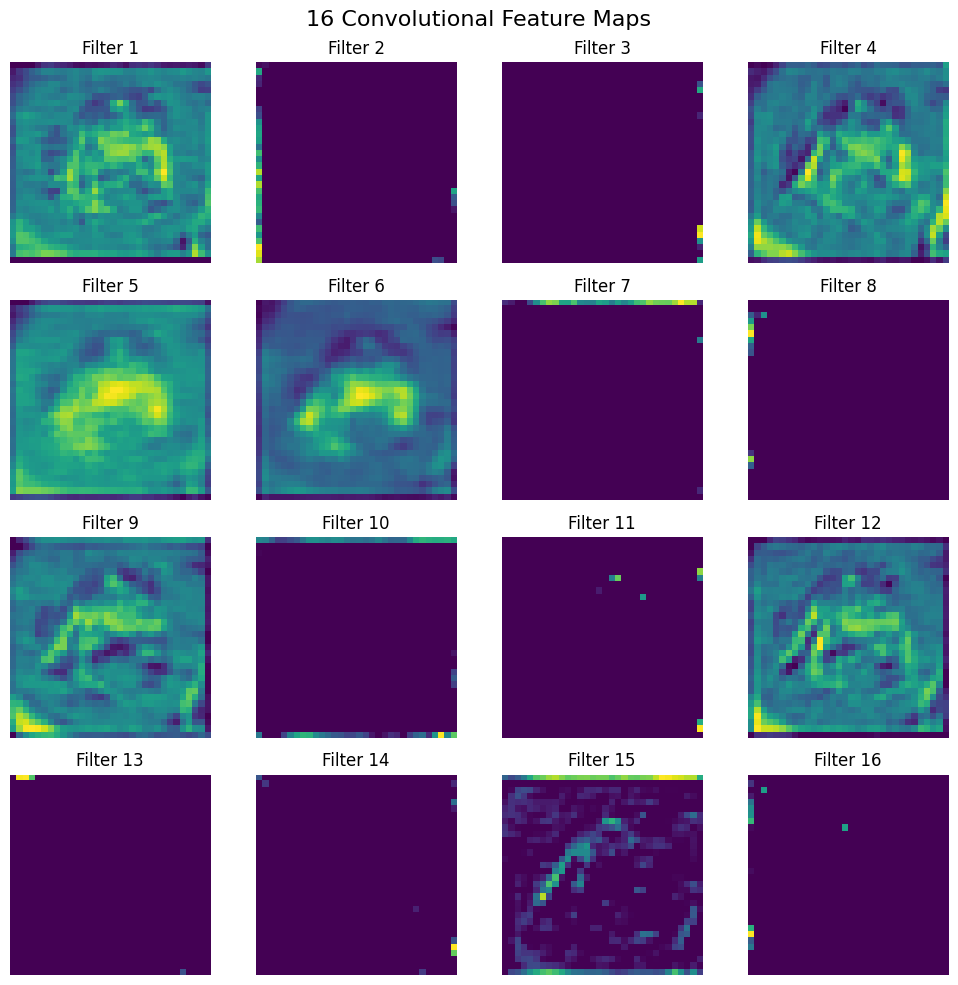

In [11]:
# A2.4 Visualise 16 feature maps
model_vis = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(16, (3, 3), activation="relu", padding="same")
])

feature_maps = model_vis(test_img, training=False).numpy()[0]
print("Feature map tensor:", feature_maps.shape)

fig, axes = plt.subplots(4, 4, figsize=(10, 10))
for i, ax in enumerate(axes.flat):
    ax.imshow(feature_maps[:, :, i], cmap="viridis")
    ax.set_title(f"Filter {i+1}")
    ax.axis("off")
fig.suptitle("16 Convolutional Feature Maps", fontsize=16)
plt.tight_layout()
plt.show()

# Task A3 — Pooling, Flatten & CNN Architecture

**Objective:** Compare MaxPooling and AveragePooling, demonstrate Flatten, implement LeNet-5, and build a modern custom CNN.

**Comment:** MaxPooling keeps the strongest activation in each 2×2 region, while AveragePooling calculates the mean. Flatten converts a 3-D feature tensor into a 1-D vector for Dense layers. LeNet-5 is a historically important CNN architecture using convolution, average pooling and tanh. The custom CNN uses stacked 3×3 convolution layers, ReLU, MaxPooling and GlobalAveragePooling.

**Expected output:** Pooling feature maps, Flatten shapes, LeNet-5 summary and parameter checks, and custom CNN summary with fewer than 2 million parameters.

Before pooling: (32, 32, 16)
After MaxPooling: (16, 16, 16)
After AveragePooling: (16, 16, 16)


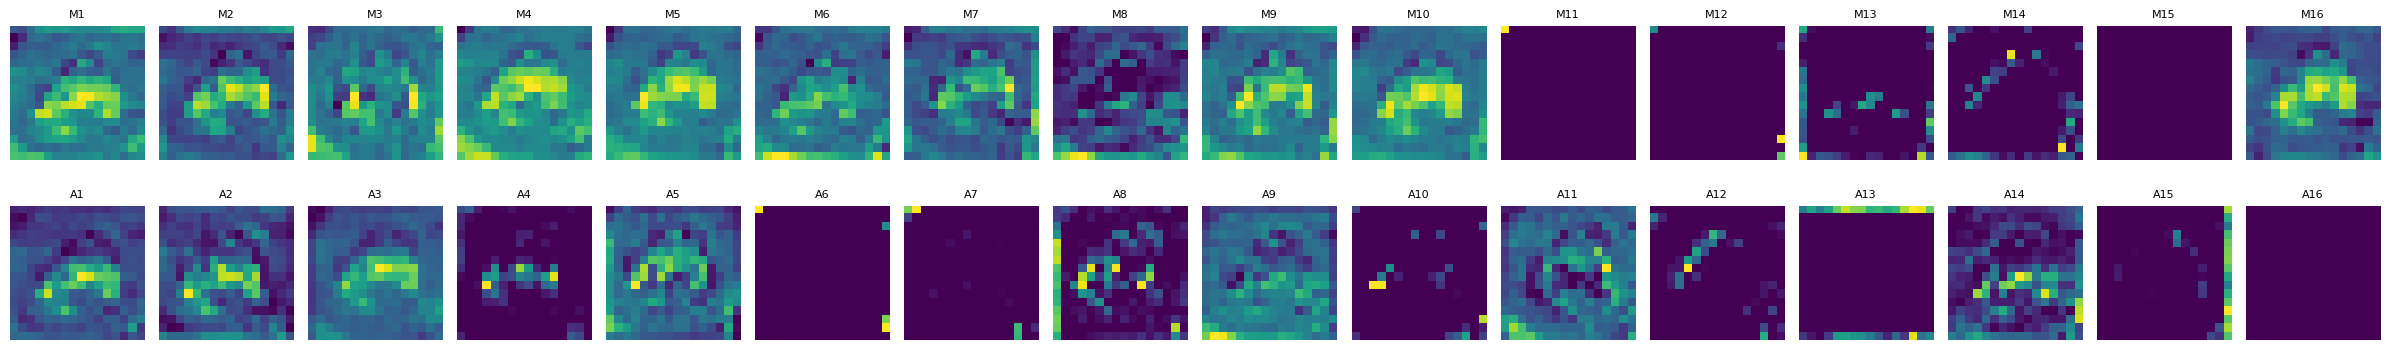

In [12]:
# A3.1 MaxPooling vs AveragePooling
max_model = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(16, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2))
])

avg_model = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(16, (3, 3), activation="relu", padding="same"),
    layers.AveragePooling2D((2, 2))
])

max_maps = max_model(test_img).numpy()[0]
avg_maps = avg_model(test_img).numpy()[0]

print("Before pooling: (32, 32, 16)")
print("After MaxPooling:", max_maps.shape)
print("After AveragePooling:", avg_maps.shape)

fig, axes = plt.subplots(2, 16, figsize=(24, 4))
for i in range(16):
    axes[0, i].imshow(max_maps[:, :, i], cmap="viridis")
    axes[0, i].axis("off")
    axes[0, i].set_title(f"M{i+1}", fontsize=8)
    axes[1, i].imshow(avg_maps[:, :, i], cmap="viridis")
    axes[1, i].axis("off")
    axes[1, i].set_title(f"A{i+1}", fontsize=8)
axes[0, 0].set_ylabel("Max")
axes[1, 0].set_ylabel("Avg")
plt.tight_layout()
plt.show()

In [13]:
# A3.2 Flatten shape demonstration
flatten_model = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(16, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten()
])

before_flatten = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(16, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2))
])(test_img)

after_flatten = flatten_model(test_img)

print("Before Flatten:", before_flatten.shape)
print("After Flatten :", after_flatten.shape)

Before Flatten: (1, 16, 16, 16)
After Flatten : (1, 4096)


In [14]:
# A3.3 LeNet-5 adapted to CIFAR-10
lenet5 = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(6, (5, 5), activation="tanh"),
    layers.AveragePooling2D((2, 2)),
    layers.Conv2D(16, (5, 5), activation="tanh"),
    layers.AveragePooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(120, activation="tanh"),
    layers.Dense(84, activation="tanh"),
    layers.Dense(10, activation="softmax")
], name="LeNet5_CIFAR10")

lenet5.summary()

Model: "LeNet5_CIFAR10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_9 (Conv2D)               │ (None, 28, 28, 6)      │           456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 14, 14, 6)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 10, 10, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_2             │ (None, 5, 5, 16)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 120)            │        48,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 62,006 (242.21 KB)

 Trainable params: 62,006 (242.21 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
# A3.4 Modern custom CNN baseline
def build_custom_cnn():
    model = keras.Sequential([
        keras.Input(shape=(32, 32, 3)),
        layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
        layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
        layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
        layers.GlobalAveragePooling2D(),

        layers.Dense(256, activation="relu"),
        layers.Dense(10, activation="softmax")
    ], name="Custom_CNN")
    return model

model_cnn = build_custom_cnn()
model_cnn.summary()

print("Total parameters:", model_cnn.count_params())
print("Requirement: < 2,000,000 parameters")

Model: "Custom_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_11 (Conv2D)              │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 175,018 (683.66 KB)

 Trainable params: 175,018 (683.66 KB)

 Non-trainable params: 0 (0.00 B)

Total parameters: 175018
Requirement: < 2,000,000 parameters


# Task A4 — Backpropagation & Training

**Objective:** Explain CNN backpropagation, train the custom CNN, plot training curves, evaluate the test set, and analyse errors.

**Comment:** During the forward pass, the image passes through convolution, activation, pooling and classification layers. During backpropagation, gradients flow backwards to update trainable weights. In MaxPooling, only the maximum location receives the gradient. In AveragePooling, the gradient is distributed across the pooling window. EarlyStopping stops training when validation loss stops improving, while ReduceLROnPlateau reduces the learning rate.

**Expected output:** Trained CNN, training/validation curves, test accuracy, confusion matrix, top confused class pairs, and 10 misclassified images.

In [16]:
# A4.2 Compile and train CNN
model_cnn.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

es = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
    verbose=1
)

rlrop = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

history = model_cnn.fit(
    X_train, y_train_ohe,
    epochs=100,
    batch_size=64,
    validation_split=0.1,
    callbacks=[es, rlrop],
    verbose=1
)

Epoch 1/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 2411s 3s/step - accuracy: 0.3383 - loss: 1.7393 - val_accuracy: 0.4542 - val_loss: 1.4290 - learning_rate: 0.0010
Epoch 2/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 91s 130ms/step - accuracy: 0.5127 - loss: 1.3238 - val_accuracy: 0.5182 - val_loss: 1.2778 - learning_rate: 0.0010
Epoch 3/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 171s 170ms/step - accuracy: 0.5920 - loss: 1.1280 - val_accuracy: 0.6190 - val_loss: 1.0658 - learning_rate: 0.0010
Epoch 4/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 176s 249ms/step - accuracy: 0.6427 - loss: 1.0027 - val_accuracy: 0.6456 - val_loss: 0.9945 - learning_rate: 0.0010
Epoch 5/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 188s 229ms/step - accuracy: 0.6778 - loss: 0.9128 - val_accuracy: 0.6764 - val_loss: 0.9210 - learning_rate: 0.0010
Epoch 6/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 124s 176ms/step - accuracy: 0.7014 - loss: 0.8443 - val_accuracy: 0.6912 - val_loss: 0.8783 - learning_rate: 0.0010
Epoch 7/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 170s 216ms/step - ac

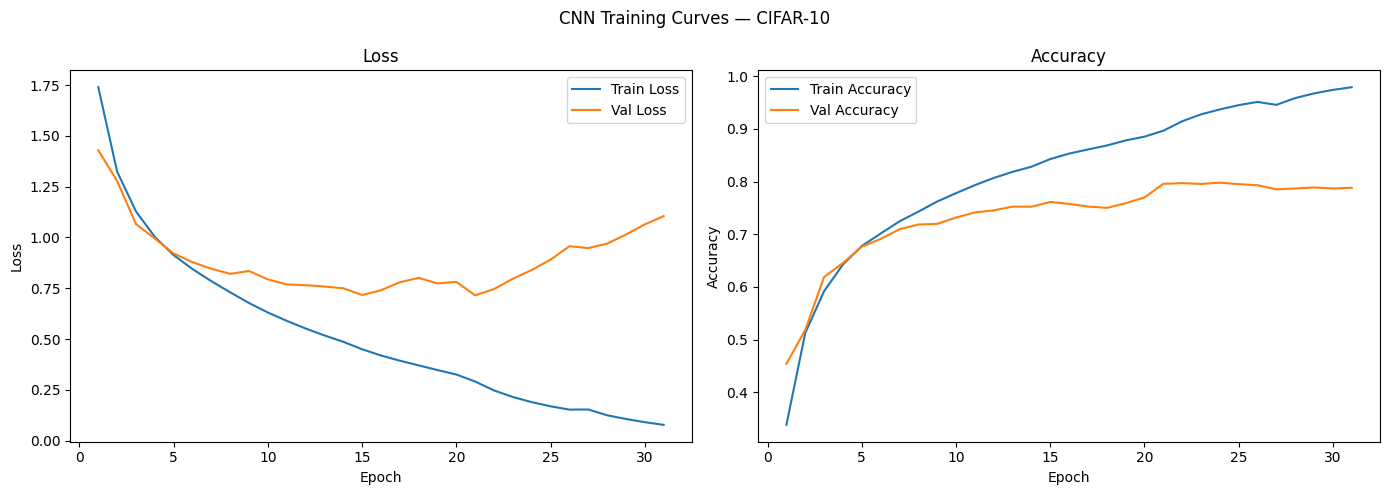

Final train accuracy: 0.9793
Final validation accuracy: 0.7884
Best validation accuracy: 0.7980


In [17]:
# A4.3 Training curves with callback event markers
hist = history.history
epochs_ran = len(hist["loss"])
epoch_axis = np.arange(1, epochs_ran + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epoch_axis, hist["loss"], label="Train Loss")
axes[0].plot(epoch_axis, hist["val_loss"], label="Val Loss")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(epoch_axis, hist["accuracy"], label="Train Accuracy")
axes[1].plot(epoch_axis, hist["val_accuracy"], label="Val Accuracy")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

fig.suptitle("CNN Training Curves — CIFAR-10")
plt.tight_layout()
plt.show()

print(f"Final train accuracy: {hist['accuracy'][-1]:.4f}")
print(f"Final validation accuracy: {hist['val_accuracy'][-1]:.4f}")
print(f"Best validation accuracy: {max(hist['val_accuracy']):.4f}")

Test loss: 0.7267
Test accuracy: 0.7880


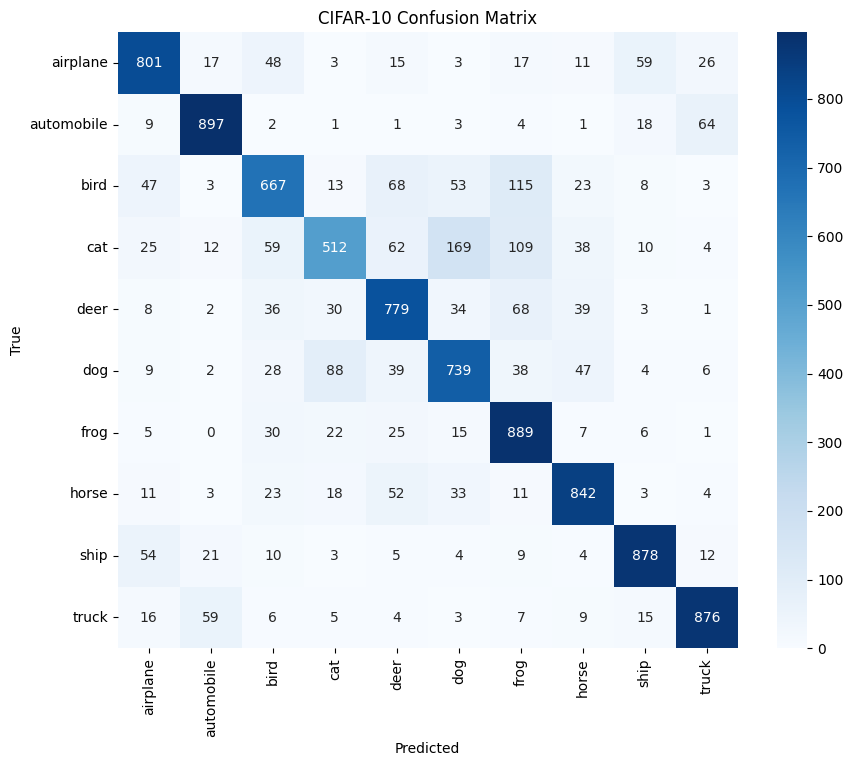

Top 3 confused class pairs:
cat ↔ dog: 257 total confusions
bird ↔ frog: 145 total confusions
cat ↔ frog: 131 total confusions

Classification report:
              precision    recall  f1-score   support

    airplane       0.81      0.80      0.81      1000
  automobile       0.88      0.90      0.89      1000
        bird       0.73      0.67      0.70      1000
         cat       0.74      0.51      0.60      1000
        deer       0.74      0.78      0.76      1000
         dog       0.70      0.74      0.72      1000
        frog       0.70      0.89      0.78      1000
       horse       0.82      0.84      0.83      1000
        ship       0.87      0.88      0.88      1000
       truck       0.88      0.88      0.88      1000

    accuracy                           0.79     10000
   macro avg       0.79      0.79      0.78     10000
weighted avg       0.79      0.79      0.78     10000



In [18]:
# A4.4 Evaluate and analyse
test_loss, test_acc = model_cnn.evaluate(X_test, y_test_ohe, verbose=0)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.4f}")

y_prob = model_cnn.predict(X_test, batch_size=128, verbose=0)
y_pred = np.argmax(y_prob, axis=1)
y_true = y_test.flatten()

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=class_names, yticklabels=class_names
)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("CIFAR-10 Confusion Matrix")
plt.show()

# Find top 3 confused class pairs
cm_no_diag = cm.copy()
np.fill_diagonal(cm_no_diag, 0)

pairs = []
for i in range(10):
    for j in range(i + 1, 10):
        count = cm_no_diag[i, j] + cm_no_diag[j, i]
        pairs.append((count, class_names[i], class_names[j]))

print("Top 3 confused class pairs:")
for count, a, b in sorted(pairs, reverse=True)[:3]:
    print(f"{a} ↔ {b}: {count} total confusions")

print("\nClassification report:")
print(classification_report(y_true, y_pred, target_names=class_names))

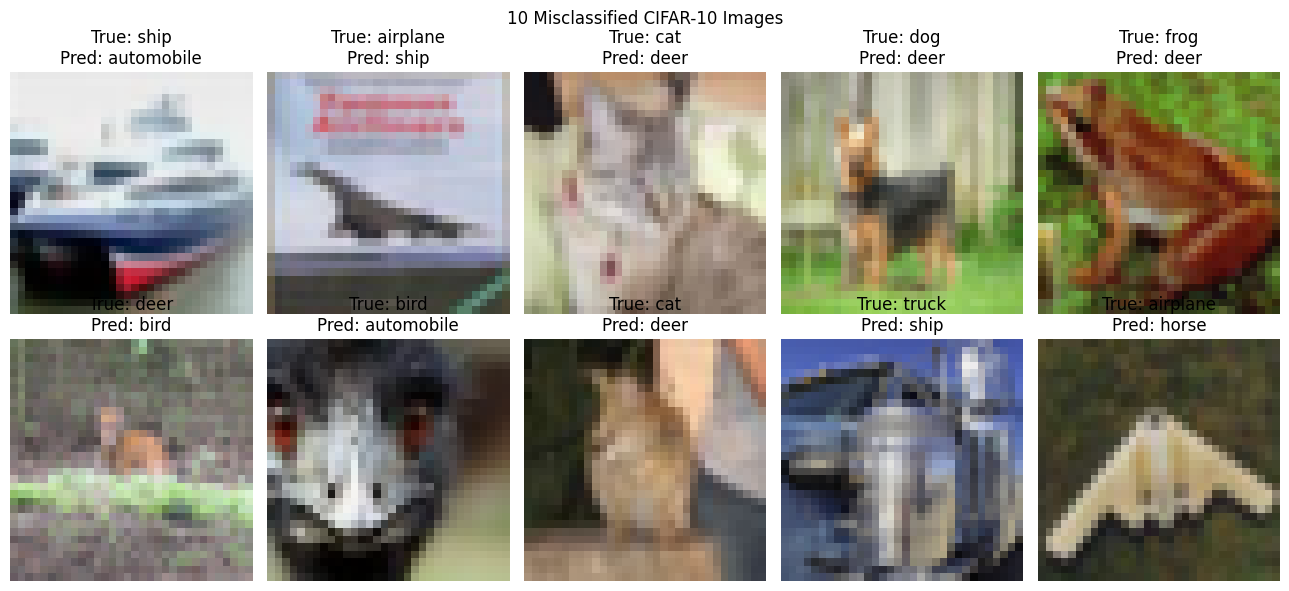

In [19]:
# Display 10 misclassified images
wrong = np.where(y_true != y_pred)[0][:10]

fig, axes = plt.subplots(2, 5, figsize=(13, 6))
for ax, idx in zip(axes.flat, wrong):
    ax.imshow(X_test[idx])
    ax.set_title(
        f"True: {class_names[y_true[idx]]}\n"
        f"Pred: {class_names[y_pred[idx]]}"
    )
    ax.axis("off")

fig.suptitle("10 Misclassified CIFAR-10 Images")
plt.tight_layout()
plt.show()

# Task A5 — Data Augmentation

**Objective:** Apply image augmentation, visualise transformed images, retrain the CNN, compare results, and demonstrate Keras preprocessing layers.

**Comment:** Data augmentation creates different versions of training images using transformations such as rotation, shifting, zoom and horizontal flipping. This increases the effective variety of the training data and helps reduce overfitting. Keras preprocessing layers perform these transformations during training and are inactive during inference.

**Expected output:** Original plus 9 augmented images, augmented CNN training, comparison curves, and test accuracy for the Keras augmentation model.

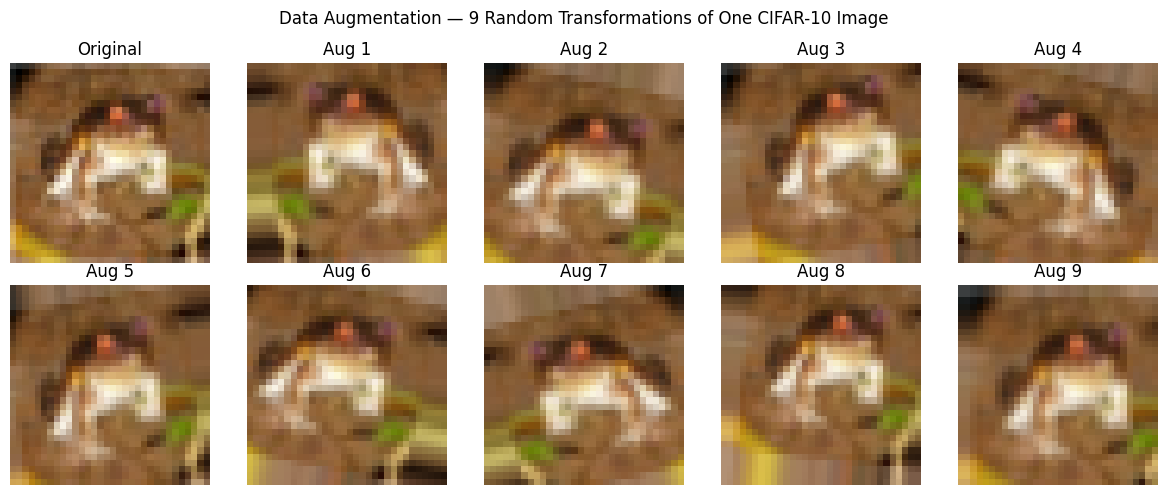

In [20]:
# A5.2 ImageDataGenerator augmentation
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    zoom_range=0.1,
    fill_mode="nearest"
)

datagen.fit(X_train)

img = X_train[0]
generator = datagen.flow(
    img[np.newaxis, ...],
    batch_size=1,
    seed=SEED
)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
axes[0, 0].imshow(img)
axes[0, 0].set_title("Original")
axes[0, 0].axis("off")

for k in range(1, 10):
    aug = next(generator)[0]
    axes.flat[k].imshow(aug)
    axes.flat[k].set_title(f"Aug {k}")
    axes.flat[k].axis("off")

fig.suptitle("Data Augmentation — 9 Random Transformations of One CIFAR-10 Image")
plt.tight_layout()
plt.show()

In [21]:
# A5.3 Retrain the same CNN with ImageDataGenerator
model_aug = build_custom_cnn()
model_aug.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

history_aug = model_aug.fit(
    datagen.flow(X_train, y_train_ohe, batch_size=64, shuffle=True, seed=SEED),
    epochs=100,
    validation_data=(X_test, y_test_ohe),
    callbacks=[es, rlrop],
    verbose=1
)

aug_test_loss, aug_test_acc = model_aug.evaluate(
    X_test, y_test_ohe, verbose=0
)
print(f"Augmented CNN test accuracy: {aug_test_acc:.4f}")

Epoch 1/100
782/782 ━━━━━━━━━━━━━━━━━━━━ 188s 235ms/step - accuracy: 0.3173 - loss: 1.7972 - val_accuracy: 0.4719 - val_loss: 1.4034 - learning_rate: 0.0010
Epoch 2/100
782/782 ━━━━━━━━━━━━━━━━━━━━ 173s 220ms/step - accuracy: 0.4869 - loss: 1.3959 - val_accuracy: 0.5465 - val_loss: 1.2384 - learning_rate: 0.0010
Epoch 3/100
782/782 ━━━━━━━━━━━━━━━━━━━━ 149s 190ms/step - accuracy: 0.5525 - loss: 1.2385 - val_accuracy: 0.5699 - val_loss: 1.1912 - learning_rate: 0.0010
Epoch 4/100
782/782 ━━━━━━━━━━━━━━━━━━━━ 26560s 34s/step - accuracy: 0.5966 - loss: 1.1265 - val_accuracy: 0.6218 - val_loss: 1.0577 - learning_rate: 0.0010
Epoch 5/100
782/782 ━━━━━━━━━━━━━━━━━━━━ 118s 151ms/step - accuracy: 0.6253 - loss: 1.0476 - val_accuracy: 0.6401 - val_loss: 1.0194 - learning_rate: 0.0010
Epoch 6/100
782/782 ━━━━━━━━━━━━━━━━━━━━ 139s 178ms/step - accuracy: 0.6554 - loss: 0.9726 - val_accuracy: 0.6660 - val_loss: 0.9499 - learning_rate: 0.0010
Epoch 7/100
782/782 ━━━━━━━━━━━━━━━━━━━━ 166s 209ms/step -

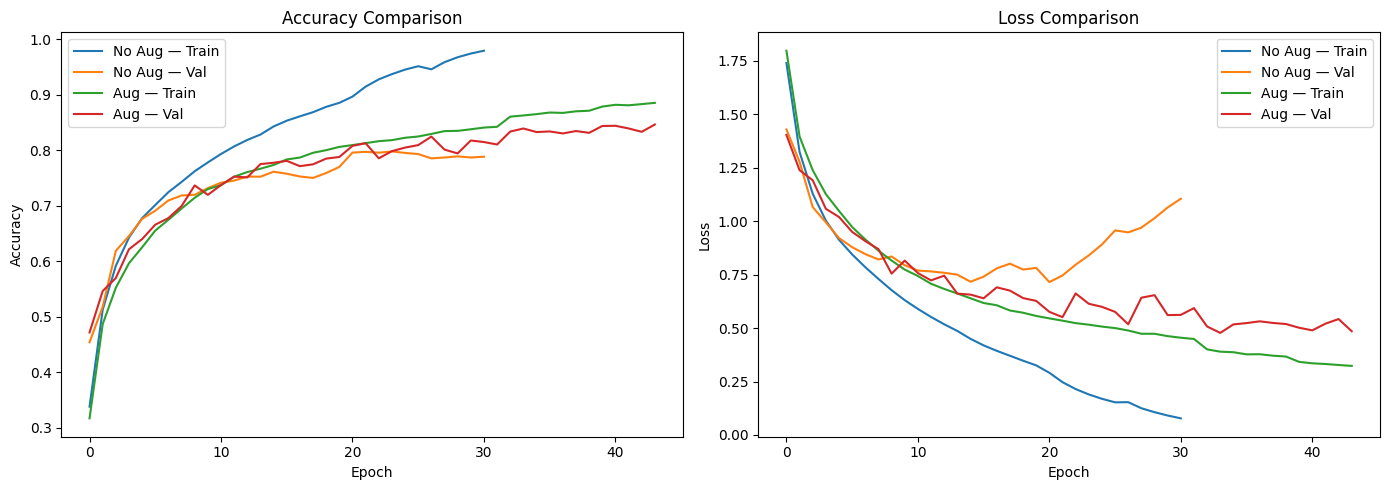

In [22]:
# Compare no augmentation vs augmentation
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history["accuracy"], label="No Aug — Train")
axes[0].plot(history.history["val_accuracy"], label="No Aug — Val")
axes[0].plot(history_aug.history["accuracy"], label="Aug — Train")
axes[0].plot(history_aug.history["val_accuracy"], label="Aug — Val")
axes[0].set_title("Accuracy Comparison")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(history.history["loss"], label="No Aug — Train")
axes[1].plot(history.history["val_loss"], label="No Aug — Val")
axes[1].plot(history_aug.history["loss"], label="Aug — Train")
axes[1].plot(history_aug.history["val_loss"], label="Aug — Val")
axes[1].set_title("Loss Comparison")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()

In [23]:
# A5.4 Modern Keras preprocessing layers
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.1, 0.1)
], name="data_augmentation")

def build_keras_aug_model():
    inputs = keras.Input(shape=(32, 32, 3))
    x = data_augmentation(inputs)
    x = layers.Conv2D(32, 3, activation="relu", padding="same")(x)
    x = layers.Conv2D(32, 3, activation="relu", padding="same")(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Conv2D(64, 3, activation="relu", padding="same")(x)
    x = layers.Conv2D(64, 3, activation="relu", padding="same")(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Conv2D(128, 3, activation="relu", padding="same")(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    outputs = layers.Dense(10, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="CNN_Keras_Augmentation")

model_keras_aug = build_keras_aug_model()
model_keras_aug.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

history_keras_aug = model_keras_aug.fit(
    X_train, y_train_ohe,
    epochs=100,
    batch_size=64,
    validation_split=0.1,
    callbacks=[es, rlrop],
    verbose=1
)

keras_aug_test_acc = model_keras_aug.evaluate(
    X_test, y_test_ohe, verbose=0
)[1]

print(f"Keras-layer augmentation test accuracy: {keras_aug_test_acc:.4f}")

Epoch 1/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 148s 202ms/step - accuracy: 0.2947 - loss: 1.8667 - val_accuracy: 0.3190 - val_loss: 1.8536 - learning_rate: 0.0010
Epoch 2/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 139s 197ms/step - accuracy: 0.4270 - loss: 1.5516 - val_accuracy: 0.4122 - val_loss: 1.6497 - learning_rate: 0.0010
Epoch 3/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 141s 195ms/step - accuracy: 0.4911 - loss: 1.3983 - val_accuracy: 0.4914 - val_loss: 1.4338 - learning_rate: 0.0010
Epoch 4/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 293s 416ms/step - accuracy: 0.5297 - loss: 1.2977 - val_accuracy: 0.4996 - val_loss: 1.4745 - learning_rate: 0.0010
Epoch 5/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 87s 123ms/step - accuracy: 0.5611 - loss: 1.2188 - val_accuracy: 0.5230 - val_loss: 1.4439 - learning_rate: 0.0010
Epoch 6/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 81s 114ms/step - accuracy: 0.5840 - loss: 1.1661 - val_accuracy: 0.5790 - val_loss: 1.2279 - learning_rate: 0.0010
Epoch 7/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 77s 109ms/step - ac

# Task A6 — Transfer Learning & Fine-Tuning

**Objective:** Use MobileNetV2 for feature extraction, fine-tune its top layers, compare all models, and demonstrate a residual connection.

**Comment:** Transfer learning reuses visual features learned from a large dataset. In feature extraction, the pretrained MobileNetV2 base is frozen and a new classification head is trained. In fine-tuning, the top 30 layers are unfrozen and trained with a very small learning rate so the pretrained weights are adjusted gradually. Residual connections add a shortcut path that helps gradients flow through deeper networks.

**Expected output:** MobileNetV2 feature-extraction model, fine-tuned model, combined training curves, six-model comparison table, and residual-block model.

In [24]:
# A6.2 MobileNetV2 feature extraction
# Use tf.data resizing to avoid creating a huge 50,000×96×96×3 array in RAM.

IMG_SIZE = (96, 96)
BATCH_SIZE = 64

base_model = keras.applications.MobileNetV2(
    input_shape=(96, 96, 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False

inputs = keras.Input(shape=(32, 32, 3))
x = layers.Resizing(96, 96)(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation="relu")(x)
outputs = layers.Dense(10, activation="softmax")(x)

model_fe = keras.Model(inputs, outputs, name="MobileNetV2_Feature_Extraction")

model_fe.summary()
print("Total parameters:", model_fe.count_params())
print("Trainable parameters:", np.sum([np.prod(v.shape) for v in model_fe.trainable_weights]))

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "MobileNetV2_Feature_Extraction"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_15 (InputLayer)     │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resizing (Resizing)             │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,423,242 (9.24 MB)

 Trainable params: 165,258 (645.54 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Total parameters: 2423242
Trainable parameters: 165258


In [25]:
# A6.3 Train feature extraction model
model_fe.compile(
    optimizer=keras.optimizers.Adam(0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

history_fe = model_fe.fit(
    X_train, y_train_ohe,
    epochs=20,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

fe_test_acc = model_fe.evaluate(X_test, y_test_ohe, verbose=0)[1]
print(f"MobileNetV2 Feature Extraction test accuracy: {fe_test_acc:.4f}")

Epoch 1/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 302s 411ms/step - accuracy: 0.7500 - loss: 0.7171 - val_accuracy: 0.7804 - val_loss: 0.6211
Epoch 2/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 11403s 16s/step - accuracy: 0.8078 - loss: 0.5498 - val_accuracy: 0.7976 - val_loss: 0.5804
Epoch 3/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 249s 354ms/step - accuracy: 0.8306 - loss: 0.4872 - val_accuracy: 0.8006 - val_loss: 0.5790
Epoch 4/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 242s 344ms/step - accuracy: 0.8476 - loss: 0.4383 - val_accuracy: 0.7984 - val_loss: 0.5810
Epoch 5/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 243s 346ms/step - accuracy: 0.8628 - loss: 0.3956 - val_accuracy: 0.8006 - val_loss: 0.5918
Epoch 6/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 303s 403ms/step - accuracy: 0.8770 - loss: 0.3607 - val_accuracy: 0.8024 - val_loss: 0.5996
Epoch 7/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 330s 414ms/step - accuracy: 0.8891 - loss: 0.3246 - val_accuracy: 0.8040 - val_loss: 0.6184
Epoch 8/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 299s 425ms/step - accuracy: 0.9007 -

In [26]:
# A6.4 Fine-tune the top 30 layers
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

model_fe.compile(
    optimizer=keras.optimizers.Adam(1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

history_ft = model_fe.fit(
    X_train, y_train_ohe,
    epochs=10,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

ft_test_acc = model_fe.evaluate(X_test, y_test_ohe, verbose=0)[1]
print(f"MobileNetV2 Fine-Tuned test accuracy: {ft_test_acc:.4f}")

Epoch 1/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 554s 369ms/step - accuracy: 0.6872 - loss: 3.0290 - val_accuracy: 0.7702 - val_loss: 1.7884
Epoch 2/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 480s 341ms/step - accuracy: 0.7970 - loss: 1.3671 - val_accuracy: 0.7658 - val_loss: 1.8159
Epoch 3/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 542s 385ms/step - accuracy: 0.8628 - loss: 0.7400 - val_accuracy: 0.7650 - val_loss: 1.7659
Epoch 4/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 556s 381ms/step - accuracy: 0.9178 - loss: 0.3926 - val_accuracy: 0.7642 - val_loss: 1.7187
Epoch 5/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 519s 350ms/step - accuracy: 0.9579 - loss: 0.1952 - val_accuracy: 0.7682 - val_loss: 1.6941
Epoch 6/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 402s 286ms/step - accuracy: 0.9818 - loss: 0.0907 - val_accuracy: 0.7712 - val_loss: 1.6690
Epoch 7/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 400s 284ms/step - accuracy: 0.9938 - loss: 0.0383 - val_accuracy: 0.7754 - val_loss: 1.6639
Epoch 8/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 396s 281ms/step - ac

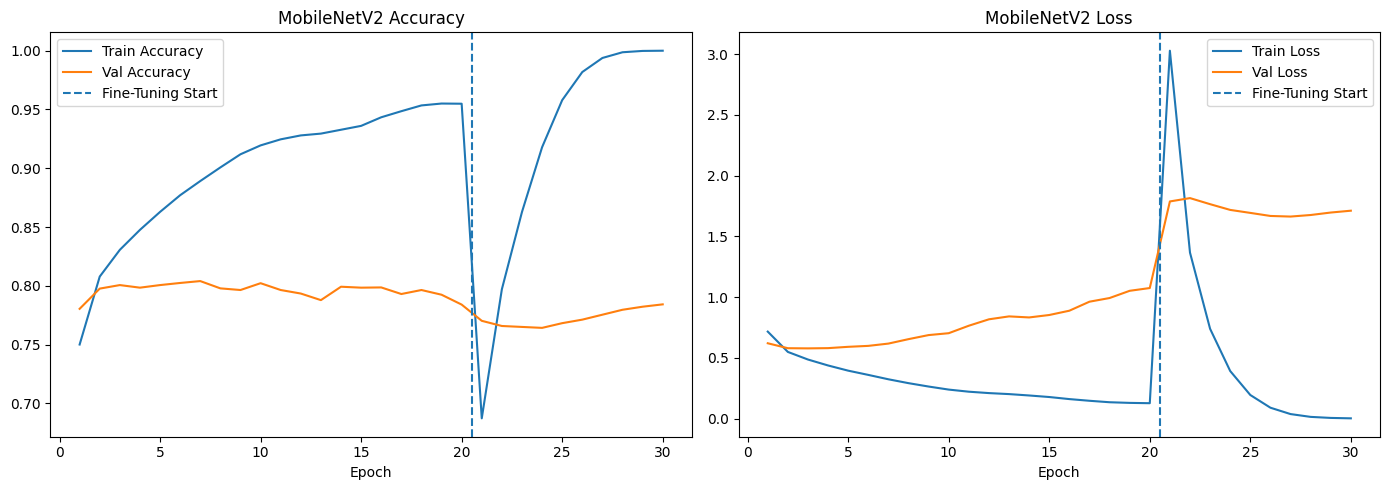

In [27]:
# A6.4 Concatenated Feature Extraction + Fine-Tuning curves
fe_epochs = np.arange(1, len(history_fe.history["accuracy"]) + 1)
ft_epochs = np.arange(
    len(fe_epochs) + 1,
    len(fe_epochs) + len(history_ft.history["accuracy"]) + 1
)

combined_train_acc = (
    history_fe.history["accuracy"] +
    history_ft.history["accuracy"]
)
combined_val_acc = (
    history_fe.history["val_accuracy"] +
    history_ft.history["val_accuracy"]
)

combined_train_loss = (
    history_fe.history["loss"] +
    history_ft.history["loss"]
)
combined_val_loss = (
    history_fe.history["val_loss"] +
    history_ft.history["val_loss"]
)

all_epochs = np.arange(1, len(combined_train_acc) + 1)
fine_tune_start = len(fe_epochs) + 0.5

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(all_epochs, combined_train_acc, label="Train Accuracy")
axes[0].plot(all_epochs, combined_val_acc, label="Val Accuracy")
axes[0].axvline(
    fine_tune_start, linestyle="--",
    label="Fine-Tuning Start"
)
axes[0].set_title("MobileNetV2 Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(all_epochs, combined_train_loss, label="Train Loss")
axes[1].plot(all_epochs, combined_val_loss, label="Val Loss")
axes[1].axvline(
    fine_tune_start, linestyle="--",
    label="Fine-Tuning Start"
)
axes[1].set_title("MobileNetV2 Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

In [28]:
# A6.5 Full results comparison table
# LeNet is not trained above to save time; train it here for a genuine test result.
lenet5.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

history_lenet = lenet5.fit(
    X_train, y_train_ohe,
    epochs=20,
    batch_size=64,
    validation_split=0.1,
    callbacks=[EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)],
    verbose=1
)
lenet_test_acc = lenet5.evaluate(X_test, y_test_ohe, verbose=0)[1]

results = pd.DataFrame([
    ["LeNet-5", "LeNet-5", "No", "No", lenet_test_acc, lenet5.count_params()],
    ["CNN Scratch No Aug", "Custom CNN", "No", "No", test_acc, model_cnn.count_params()],
    ["CNN Scratch + Aug", "Custom CNN", "ImageDataGenerator", "No", aug_test_acc, model_aug.count_params()],
    ["CNN + Keras Aug Layers", "Custom CNN", "Keras layers", "No", keras_aug_test_acc, model_keras_aug.count_params()],
    ["MobileNetV2 Feature Extraction", "MobileNetV2", "No", "Feature Extraction", fe_test_acc, model_fe.count_params()],
    ["MobileNetV2 Fine-Tuned", "MobileNetV2", "No", "Fine-Tuning", ft_test_acc, model_fe.count_params()],
], columns=[
    "Model", "Architecture", "Augmentation",
    "Transfer Learning", "Test Accuracy", "Parameters"
])

display(
    results.style
    .format({"Test Accuracy": "{:.4f}", "Parameters": "{:,}"})
    .highlight_max(subset=["Test Accuracy"])
)

results.to_csv("model_results.csv", index=False)

Epoch 1/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 12s 13ms/step - accuracy: 0.3596 - loss: 1.8148 - val_accuracy: 0.3802 - val_loss: 1.7463
Epoch 2/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.4262 - loss: 1.6261 - val_accuracy: 0.4368 - val_loss: 1.5878
Epoch 3/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.4707 - loss: 1.4958 - val_accuracy: 0.4766 - val_loss: 1.4782
Epoch 4/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.5020 - loss: 1.4070 - val_accuracy: 0.4984 - val_loss: 1.4230
Epoch 5/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.5253 - loss: 1.3423 - val_accuracy: 0.5096 - val_loss: 1.3900
Epoch 6/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.5435 - loss: 1.2895 - val_accuracy: 0.5138 - val_loss: 1.3641
Epoch 7/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.5590 - loss: 1.2442 - val_accuracy: 0.5216 - val_loss: 1.3509
Epoch 8/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.5748 - loss: 1.2054 - val_acc

,Model,Architecture,Augmentation,Transfer Learning,Test Accuracy,Parameters
0,LeNet-5,LeNet-5,No,No,0.5212,"62,006"
1,CNN Scratch No Aug,Custom CNN,No,No,0.7880,"175,018"
2,CNN Scratch + Aug,Custom CNN,ImageDataGenerator,No,0.8392,"175,018"
3,CNN + Keras Aug Layers,Custom CNN,Keras layers,No,0.7820,"175,018"
4,MobileNetV2 Feature Extraction,MobileNetV2,No,Feature Extraction,0.7874,"2,423,242"
5,MobileNetV2 Fine-Tuned,MobileNetV2,No,Fine-Tuning,0.7823,"2,423,242"


In [29]:
# A6.6 Minimal residual connection block
inputs = keras.Input(shape=(32, 32, 64))

shortcut = layers.Conv2D(
    64, (1, 1), padding="same", activation=None
)(inputs)

x = layers.Conv2D(
    64, (3, 3), padding="same", activation="relu"
)(inputs)
x = layers.Conv2D(
    64, (3, 3), padding="same", activation="relu"
)(x)

x = layers.Add()([shortcut, x])
outputs = layers.Activation("relu")(x)

residual_model = keras.Model(
    inputs, outputs, name="Minimal_Residual_Block"
)

residual_model.summary()

Model: "Minimal_Residual_Block"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_16      │ (None, 32, 32,    │          0 │ -                 │
│ (InputLayer)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_27 (Conv2D)  │ (None, 32, 32,    │     36,928 │ input_layer_16[0… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_26 (Conv2D)  │ (None, 32, 32,    │      4,160 │ input_layer_16[0… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_28 (Conv2D)  │ (None, 32, 32,    │     36,928 │ conv2d_27[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 32, 32,    │          0 │ conv2d_26[0][0],  │
│                     │ 64)               │            │ conv2d_28[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 32, 32,    │          0 │ add[0][0]         │
│ (Activation)        │ 64)               │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 78,016 (304.75 KB)

 Trainable params: 78,016 (304.75 KB)

 Non-trainable params: 0 (0.00 B)